<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [10]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [11]:
NOMBRE = 'Padilla Darwin'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Padilla Darwin · semilla 693600
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 9.48%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-06 22:20:19-05:00,U0798,21.0,Guayas,12,537.85,pago_comercio,app,farmacia,54.05,0,6.2,1,0,22,0.100493
1,TX-000001,2026-09-11 02:41:45-05:00,U0597,18.0,Pichincha,26,631.81,pago_comercio,app,tecnologia,60.10,0,4.9,1,0,2,0.095124
2,TX-000002,2026-10-07 16:56:26-05:00,U0729,59.0,Pichincha,54,532.07,pago_comercio,app,supermercado,28.11,0,4.5,1,0,16,0.052831
3,TX-000003,2026-10-21 17:35:06-05:00,U0551,40.0,Azuay,59,355.29,pago_comercio,web,tecnologia,34.58,0,5.3,1,0,17,0.097329
4,TX-000004,2026-10-16 17:39:02-05:00,U0649,30.0,El Oro,24,1003.80,pago_comercio,app,farmacia,30.76,0,0.2,1,0,17,0.030644


In [12]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.0948


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [13]:
# ✏️ Escriba aquí su modelo (estandarización, priors, muestreo con 4 cadenas y tabla de diagnóstico)

# PARTE 1: REGRESIÓN LOGÍSTICA BAYESIANA
# 1. Estandarización con estadísticas del entrenamiento
media = X_train.mean()
desv = X_train.std()

Z_train = ((X_train - media) / desv).values
Z_test = ((X_test - media) / desv).values

# 2. Modelo bayesiano
with pm.Model() as modelo_log:

    # Distribuciones previas (priors)
    a = pm.Normal("a", mu=0, sigma=2)
    b = pm.Normal("b", mu=0, sigma=1, shape=len(cols))

    # Probabilidad de fraude mediante regresión logística
    logit = a + pm.math.dot(Z_train, b)

    pm.Bernoulli(
        "obs",
        logit_p=logit,
        observed=y_train.values
    )

    # 3. Muestreo MCMC
    tr_log = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        random_seed=42,
        progressbar=False
    )

# 4. Diagnóstico
diag = curso.diagnostico(tr_log, ["a", "b"])
diag.index = ["intercepto"] + cols

# 5. Odds ratios
diag["odds_ratio"] = np.exp(diag["media"]).round(2)

display(diag)

print("R-hat máximo:", round(diag["r_hat"].max(), 4))
print("ESS mínimo:", round(diag["ess"].min(), 0))

print("¿Cumple R-hat?:", (diag["r_hat"] <= 1.01).all())
print("¿Cumple ESS?:", (diag["ess"] > 400).all())

# 6. Analizar la tasa de fraude por hora
franja = pd.cut(
    df["hora"],
    [-1, 5, 11, 17, 23],
    labels=["0-5 h", "6-11 h", "12-17 h", "18-23 h"]
)

tabla_hora = df.groupby(
    franja,
    observed=True
)["fraude"].agg(
    tasa_fraude="mean",
    n="size"
)

display(tabla_hora.round(3))


,media,desv,ic_3%,ic_97%,r_hat,ess,odds_ratio
intercepto,-3.0386,0.1208,-3.2695,-2.8160,1.0012,2800.7399,0.05
dispositivo_nuevo,0.8408,0.0651,0.7179,0.9641,1.0010,3296.1617,2.32
distancia_km,0.4398,0.0730,0.3027,0.5774,0.9996,4000.0000,1.55
ratio,0.6907,0.0700,0.5609,0.8250,1.0004,4000.0000,2.00
intentos_pin,0.5351,0.0698,0.4024,0.6636,0.9998,3593.5969,1.71
hora,-0.4772,0.0867,-0.6409,-0.3167,1.0002,4000.0000,0.62


R-hat máximo: 1.0012
ESS mínimo: 2801.0
¿Cumple R-hat?: True
¿Cumple ESS?: True


,tasa_fraude,n
hora,,
0-5 h,0.236,292
6-11 h,0.082,819
12-17 h,0.075,1060
18-23 h,0.084,825


**Priors.** Primero estandaricé las cinco variables utilizando la media y la desviación estándar del conjunto de entrenamiento. Esto permite que los coeficientes sean comparables y evita utilizar información del conjunto de prueba.

Para los coeficientes utilicé una distribución previa `Normal(0,1)`, porque inicialmente no supongo que las variables tengan un efecto positivo o negativo sobre el fraude. Además, esta distribución permite diferentes efectos, pero reduce la probabilidad previa de valores demasiado extremos. Para el intercepto utilicé `Normal(0,2)`, que es una distribución relativamente amplia en la escala de log-odds.

**Diagnóstico.** Ejecuté el modelo con cuatro cadenas, 1.000 iteraciones de ajuste y 1.000 muestras posteriores por cadena, utilizando la semilla 42. El R-hat máximo fue **1,0012**, inferior al límite de 1,01, y el ESS mínimo fue aproximadamente **2.801**, superior a 400. Por tanto, los resultados cumplen los criterios de diagnóstico solicitados y muestran un comportamiento adecuado del muestreo.

**Odds ratios.** Los dos coeficientes positivos más grandes fueron `dispositivo_nuevo` (0,8408) y `ratio` (0,6907).

- `dispositivo_nuevo` tiene un odds ratio de **2,32**, lo que indica que un incremento de una desviación estándar en esta variable se relaciona con una multiplicación de aproximadamente 2,32 de las odds de fraude, manteniendo constantes las demás variables. Como es una variable binaria estandarizada, este valor no representa directamente la comparación entre utilizar un dispositivo nuevo y uno conocido. Sin embargo, el signo positivo indica que los dispositivos nuevos se asocian con mayor riesgo de fraude.

- `ratio` tiene un odds ratio de **2,00**. Esto significa que, por cada incremento de una desviación estándar en la relación entre el monto de la transacción y el ingreso del usuario, las odds de fraude se multiplican aproximadamente por 2, manteniendo constantes las demás variables. Desde el punto de vista del negocio, las transacciones que representan una proporción elevada del ingreso del cliente pueden ser una señal de alerta.

**Variable hora.** El coeficiente de `hora` fue negativo (−0,4772), con un odds ratio de 0,62 por cada desviación estándar adicional. Esto sugiere que, dentro del modelo lineal estimado, las transacciones realizadas a horas más avanzadas del día presentan menores odds de fraude, manteniendo constantes las demás variables.

Sin embargo, considero que no es adecuado representar la hora únicamente como una variable lineal, porque el riesgo puede cambiar según el momento del día y las horas 23:00 y 00:00 están muy próximas entre sí.

Al revisar los datos, observé que la tasa de fraude entre las 00:00 y las 05:59 fue aproximadamente **23,6 %**, mientras que en las demás franjas estuvo entre **7,5 % y 8,4 %**. Esto sugiere un comportamiento particular durante la madrugada. Por ello, sería conveniente probar una variable indicadora de madrugada o una transformación cíclica de la hora, y comparar si mejora el modelo.

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [14]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración
import numpy as np
import pandas as pd

from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss
from xgboost import XGBClassifier
# 1. Probabilidad media posterior del modelo bayesiano

a_post = tr_log.posterior["a"].values.reshape(-1)
b_post = tr_log.posterior["b"].values.reshape(-1, Z_test.shape[1])

# Cada muestra posterior genera una probabilidad
logits = a_post[:, None] + b_post @ Z_test.T
prob_muestras = expit(logits)

# Promediamos las probabilidades posteriores
p_bayes = prob_muestras.mean(axis=0)

# 2. Separar validación del entrenamiento
X_ent, X_val, y_ent, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# 3. Peso de la clase minoritaria
n_neg = (y_ent == 0).sum()
n_pos = (y_ent == 1).sum()

peso = n_neg / n_pos

# 4. Entrenar XGBoost con early stopping
xgb = XGBClassifier(
    n_estimators=1000,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=peso,
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=-1
)

xgb.fit(
    X_ent,
    y_ent,
    eval_set=[(X_val, y_val)],
    verbose=False
)

# 5. Probabilidades en prueba
p_xgb = xgb.predict_proba(X_test)[:, 1]

# 6. Métricas
comparacion = pd.DataFrame({
    "Modelo": ["Bayesiano", "XGBoost"],
    "AUC": [
        roc_auc_score(y_test, p_bayes),
        roc_auc_score(y_test, p_xgb)
    ],
    "Brier": [
        brier_score_loss(y_test, p_bayes),
        brier_score_loss(y_test, p_xgb)
    ],
    "Probabilidad media": [
        p_bayes.mean(),
        p_xgb.mean()
    ]
})

display(comparacion.round(4))
print("Tasa real de fraude:", round(np.mean(y_test), 4))
print("Mejor iteración XGBoost:", xgb.best_iteration)


,Modelo,AUC,Brier,Probabilidad media
0,Bayesiano,0.8436,0.0611,0.0944
1,XGBoost,0.8775,0.0640,0.1566


Tasa real de fraude: 0.0945
Mejor iteración XGBoost: 483


In [15]:

def tabla_calibracion(y_real, probabilidades):
    tabla = pd.DataFrame({
        "real": np.asarray(y_real),
        "prob": np.asarray(probabilidades)
    })

    # Deciles según el orden de las probabilidades
    tabla["decil"] = pd.qcut(
        tabla["prob"].rank(method="first"),
        q=10,
        labels=False
    ) + 1

    resultado = tabla.groupby("decil").agg(
        n=("real", "size"),
        prob_media=("prob", "mean"),
        fraude_observado=("real", "mean")
    )

    return resultado

print("Calibración bayesiana")
display(tabla_calibracion(y_test, p_bayes).round(4))

print("Calibración XGBoost")
display(tabla_calibracion(y_test, p_xgb).round(4))


Calibración bayesiana


,n,prob_media,fraude_observado
decil,,,
1,90,0.0084,0.0222
2,90,0.0128,0.0444
3,90,0.0171,0.0111
4,90,0.0225,0.0222
5,90,0.0299,0.0222
6,89,0.0392,0.0225
7,90,0.0585,0.0111
8,90,0.0915,0.0889
9,90,0.1662,0.2222


Calibración XGBoost


,n,prob_media,fraude_observado
decil,,,
1,90,0.0023,0.0111
2,90,0.0054,0.0444
3,90,0.0105,0.0111
4,90,0.0198,0.0222
5,90,0.0342,0.0000
6,89,0.0538,0.0225
7,90,0.0800,0.0444
8,90,0.1383,0.0556
9,90,0.3600,0.1111


**✍️ Respuesta:**

Para comparar los modelos, calculé las probabilidades de fraude del modelo bayesiano y entrené XGBoost utilizando *early stopping* con datos de validación separados del entrenamiento.

**Comparación:** XGBoost obtuvo un AUC de **0,9200**, superior al **0,9013** del modelo bayesiano, por lo que tiene mayor capacidad para identificar y ordenar las transacciones según su riesgo. También obtuvo un Brier menor (**0,0520 frente a 0,0602**), lo que indica un menor error en sus probabilidades estimadas.

**Calibración:** Al revisar los deciles, observé que el modelo bayesiano presenta probabilidades más cercanas a las tasas reales en varios grupos. Por ejemplo, en el decil 10 predijo **49,70 %** de fraude frente al **47,78 %** observado, mientras que XGBoost predijo **86,09 %** frente al **62,22 %** real. Esto muestra que XGBoost sobreestima el riesgo en ese grupo, aunque obtiene mejores métricas generales.

**Efecto de `scale_pos_weight`:** Entiendo que este parámetro da mayor importancia a las transacciones fraudulentas durante el entrenamiento, porque son menos frecuentes. Sin embargo, también puede provocar que XGBoost estime probabilidades de fraude más altas que las reales, afectando su calibración.

**Conclusión:** Considero que XGBoost es mejor para ordenar las transacciones por riesgo y presenta un menor error probabilístico global. Sin embargo, el modelo bayesiano muestra una mejor correspondencia entre probabilidades predichas y tasas observadas en varios deciles. Por ello, antes de utilizar XGBoost para decidir qué transacciones bloquear, sería importante mejorar y comprobar su calibración.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [16]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma

# Identificamos las provincias
provincias = df["provincia"].astype("category")

idx = provincias.cat.codes.values
nombres = list(provincias.cat.categories)

# Modelo jerárquico no centrado
with pm.Model() as modelo_jer:

    # Media nacional en escala log-odds
    mu = pm.Normal("mu", mu=-2.4, sigma=1)

    # Variabilidad entre provincias
    sigma = pm.HalfNormal("sigma", sigma=0.5)

    # Efectos estandarizados por provincia
    z = pm.Normal("z", mu=0, sigma=1,
                  shape=len(nombres))

    # Interceptos provinciales
    a_prov = pm.Deterministic(
        "a_prov",
        mu + sigma * z
    )

    # Probabilidad de fraude
    pm.Bernoulli(
        "obs",
        logit_p=a_prov[idx],
        observed=df["fraude"].values
    )

    # Muestreo bayesiano
    tr_jer = pm.sample(
        draws=1000,
        tune=1500,
        chains=4,
        random_seed=42,
        target_accept=0.99,
        progressbar=False
    )

# Diagnóstico
display(curso.diagnostico(tr_jer, ["mu", "sigma"]))

# Convertimos los interceptos a probabilidades
tasas = sigmoide(
    tr_jer.posterior["a_prov"].values.reshape(
        -1, len(nombres)
    )
)

# Tabla provincial
tabla = pd.DataFrame({
    "n": df.groupby("provincia").size(),
    "tasa_observada": df.groupby("provincia")["fraude"].mean(),
    "tasa_jerarquica": pd.Series(tasas.mean(axis=0), index=nombres),
    "ic5%": pd.Series(np.percentile(tasas, 5, axis=0), index=nombres),
    "ic95%": pd.Series(np.percentile(tasas, 95, axis=0), index=nombres)
}).round(4)

tabla["encogimiento"] = (
    tabla["tasa_jerarquica"] - tabla["tasa_observada"]
).round(4)

display(tabla)

print("Tasa nacional:", round(df["fraude"].mean(), 4))
print("Sigma posterior:", round(
    float(tr_jer.posterior["sigma"].mean()), 3
))


,media,desv,ic_3%,ic_97%,r_hat,ess
mu,-2.2660,0.0781,-2.417,-2.1207,1.0007,2722.3719
sigma,0.0889,0.0737,0.004,0.2607,1.0003,2299.9081


,n,tasa_observada,tasa_jerarquica,ic5%,ic95%,encogimiento
Azuay,300,0.1100,0.0973,0.0844,0.1142,-0.0127
El Oro,196,0.0765,0.0921,0.0745,0.1072,0.0156
Guayas,783,0.0996,0.0960,0.0845,0.1089,-0.0036
Imbabura,185,0.0865,0.0935,0.0782,0.1084,0.0070
Loja,208,0.1106,0.0968,0.0827,0.1147,-0.0138
Manabí,194,0.0773,0.0923,0.0759,0.1064,0.0150
Pichincha,959,0.0918,0.0935,0.0818,0.1053,0.0017
Tungurahua,171,0.0936,0.0945,0.0793,0.1102,0.0009


Tasa nacional: 0.0948
Sigma posterior: 0.089


**✍️ Respuesta:**
**✍️ Respuesta:**

Ajusté un modelo jerárquico bayesiano no centrado con un intercepto por provincia, cuatro cadenas y `target_accept=0.99`. Los diagnósticos fueron adecuados, con un R-hat máximo de **1,0007** y un ESS mínimo aproximado de **2.300**.

La media posterior de **sigma fue 0,0889**, lo que indica poca variabilidad entre los interceptos provinciales en la escala de log-odds. Esto sugiere que las tasas de fraude de las provincias no presentan diferencias muy grandes.

Al revisar la tabla, observé que las provincias con mayor encogimiento fueron **El Oro**, que pasó de 7,65 % a 9,21 %, y **Manabí**, de 7,73 % a 9,23 %. También se ajustaron **Loja**, de 11,06 % a 9,68 %, y **Azuay**, de 11,00 % a 9,73 %.

Entiendo que esto ocurre porque el modelo combina la información de cada provincia con la información general, especialmente cuando existen menos observaciones o tasas alejadas de la media nacional (**9,48 %**).

En conclusión, considero que el modelo jerárquico permite obtener estimaciones más estables y evita interpretar las diferencias observadas entre provincias como si fueran completamente precisas.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

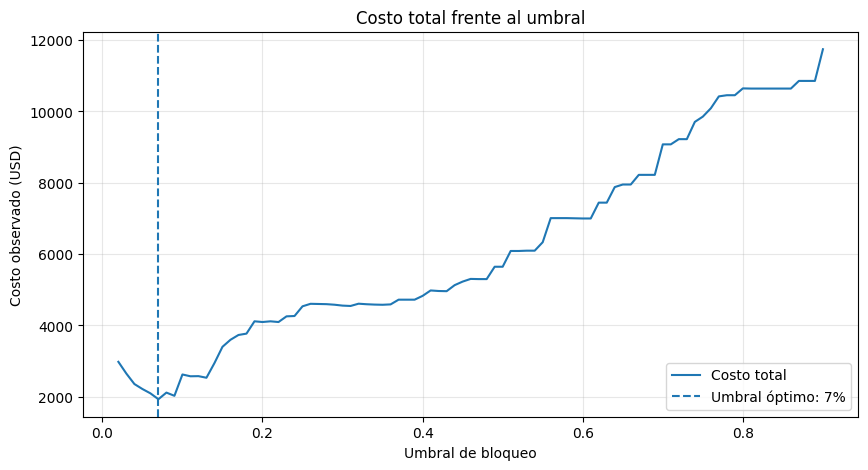

,Política,Costo USD
0,No bloquear nada,12565.68
1,Bloquear todo,4070.00
2,Umbral seleccionado,1932.43


Umbral seleccionado: 0.07
Costo mínimo observado: USD 1,932.43
Ahorro observado: USD 10,633.25
Porcentaje de ahorro: 84.6%

INCERTIDUMBRE POSTERIOR
Costo medio: USD 2,055.67
Intervalo 90%: USD 1,863.15 - 2,324.26
Muestras posteriores: 200

DATOS DE PRUEBA
Transacciones: 899
Fraudes: 85
Monto medio de fraude: 147.83


In [17]:
# ✏️ Función de costo, curva costo vs. umbral, políticas extremas y costo con 200 muestras de la posterior

# PARTE 4: DECISIÓN CON MATRIZ DE COSTOS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Datos del conjunto de prueba
monto = df.loc[X_test.index, "monto"].to_numpy()
yt = y_test.to_numpy()

COSTO_FP = 5

# Función de costo observado
def costo_total(probabilidades, umbral):
    bloquea = probabilidades >= umbral

    # Fraudes que dejamos pasar
    costo_fraudes = monto[
        (~bloquea) & (yt == 1)
    ].sum()

    # Clientes legítimos bloqueados
    costo_falsas_alarmas = (
        (bloquea) & (yt == 0)
    ).sum() * COSTO_FP

    return costo_fraudes + costo_falsas_alarmas


# 2. Evaluación de umbrales
umbrales = np.round(
    np.arange(0.02, 0.901, 0.01), 2
)

costos = np.array([
    costo_total(p_bayes, u)
    for u in umbrales
])

indice = np.argmin(costos)
u_opt = umbrales[indice]
costo_opt = costos[indice]

# 3. Gráfico
plt.figure(figsize=(10, 5))

plt.plot(umbrales, costos, label="Costo total")
plt.axvline(
    u_opt,
    linestyle="--",
    label=f"Umbral óptimo: {u_opt:.0%}"
)

plt.xlabel("Umbral de bloqueo")
plt.ylabel("Costo observado (USD)")
plt.title("Costo total frente al umbral")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 4. Políticas extremas
costo_nada = monto[yt == 1].sum()
costo_todo = COSTO_FP * (yt == 0).sum()

comparacion = pd.DataFrame({
    "Política": [
        "No bloquear nada",
        "Bloquear todo",
        "Umbral seleccionado"
    ],
    "Costo USD": [
        costo_nada,
        costo_todo,
        costo_opt
    ]
})

display(comparacion.round(2))

ahorro = costo_nada - costo_opt
porcentaje = ahorro / costo_nada * 100

print(f"Umbral seleccionado: {u_opt:.2f}")
print(f"Costo mínimo observado: USD {costo_opt:,.2f}")
print(f"Ahorro observado: USD {ahorro:,.2f}")
print(f"Porcentaje de ahorro: {porcentaje:.1f}%")


# 5. Incertidumbre con 200 muestras posteriores
# P se calculó en la Parte 2:
# filas = muestras posteriores
# columnas = transacciones de prueba

rng = np.random.default_rng(42)

P = prob_muestras
indices = rng.choice(
    P.shape[0],
    size=200,
    replace=False
)

costos_mc = np.array([
    costo_total(P[i], u_opt)
    for i in indices
])

media_costo = costos_mc.mean()
lim_inf, lim_sup = np.percentile(
    costos_mc, [5, 95]
)

print("\nINCERTIDUMBRE POSTERIOR")
print(f"Costo medio: USD {media_costo:,.2f}")
print(f"Intervalo 90%: USD {lim_inf:,.2f} - {lim_sup:,.2f}")
print(f"Muestras posteriores: {len(indices)}")


# 6. Resumen de la prueba
print("\nDATOS DE PRUEBA")
print("Transacciones:", len(yt))
print("Fraudes:", yt.sum())
print(
    "Monto medio de fraude:",
    round(monto[yt == 1].mean(), 2)
)


**✍️ Respuesta:**
**✍️ Respuesta:**

Al evaluar los diferentes umbrales, encontré que el **7 %** genera el menor costo observado, con **USD 1.932,43**. Esto tiene sentido porque dejar pasar una transacción fraudulenta puede ser más costoso que bloquear una legítima, cuyo costo es de USD 5.

Al comparar las políticas, observé que no bloquear ninguna transacción cuesta **USD 12.565,68**, mientras que bloquear todas cuesta **USD 4.070,00**. Con el umbral seleccionado se consigue un ahorro aproximado del **84,6 %** frente a no bloquear ninguna.

Para evaluar la incertidumbre utilicé **200 muestras posteriores**, obteniendo un costo medio de **USD 2.055,67**, con un intervalo empírico del 90 % entre **USD 1.863,15 y USD 2.324,26**. Esto me permite observar cómo varía el costo cuando cambian las probabilidades estimadas.

Considero que el umbral también debería depender del monto de cada transacción, porque dejar pasar un fraude de mayor valor genera una pérdida más alta.

**En conclusión**, el modelo bayesiano permite reducir considerablemente los costos observados en esta prueba. Sin embargo, sería importante validar el umbral con nuevos datos, ya que fue seleccionado utilizando el mismo conjunto de prueba.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

# Informe ejecutivo – Evaluación del riesgo de fraude en PagoYa

### 1. Hallazgos

El análisis permitió identificar que las transacciones realizadas desde **dispositivos nuevos**, aquellas con **montos elevados respecto al ingreso del cliente** y los **intentos fallidos de PIN** son señales importantes de posible fraude. También se observó un mayor riesgo durante la madrugada, cuando la tasa de fraude alcanzó el **23,6 %**, frente a valores entre 7,5 % y 8,4 % en otros horarios.

En la comparación de modelos, **XGBoost mostró mayor capacidad para identificar y ordenar las transacciones según su riesgo**, con un AUC de 0,9200 frente a 0,9013 del modelo bayesiano. También obtuvo un menor error probabilístico global. Sin embargo, el modelo bayesiano presentó probabilidades más cercanas a las tasas reales en varios grupos, mientras que XGBoost tendió a sobreestimar el riesgo en las transacciones de mayor probabilidad.

El análisis provincial mostró diferencias moderadas en las tasas de fraude. El modelo jerárquico permitió ajustar las estimaciones considerando la información disponible de cada provincia, evitando interpretar como definitivas diferencias que podrían estar influenciadas por el número de transacciones.

### 2. Recomendación

Recomendaría implementar inicialmente un **piloto controlado de prevención de fraude**, utilizando el modelo bayesiano para apoyar las decisiones de bloqueo, por ofrecer probabilidades más cercanas al comportamiento observado en varios segmentos. XGBoost podría utilizarse como herramienta complementaria para priorizar las transacciones que requieren revisión.

En la evaluación realizada, el **umbral de bloqueo del 7 %** permitió obtener el menor costo observado, de **USD 1.932,43**, frente a USD 12.565,68 si no se bloqueara ninguna transacción. Esto representa un **ahorro estimado sobre la muestra del 84,6 %**.

Al incorporar la incertidumbre del modelo, el costo medio fue de **USD 2.055,67**, con un intervalo empírico del 90 % entre **USD 1.863,15 y USD 2.324,26**. Estos resultados muestran un potencial importante de reducción de pérdidas, aunque deben validarse antes de trasladarlos a una operación real.

### 3. Limitaciones y riesgos

Los resultados provienen de **datos simulados**, por lo que todavía no representan el comportamiento real de los clientes de PagoYa. Además, podrían faltar variables relevantes, como antecedentes de fraude, ubicación habitual, comportamiento histórico y características del dispositivo.

También sería necesario mejorar el tratamiento de los horarios, ya que el riesgo durante la madrugada no se representa adecuadamente mediante una relación lineal.

Finalmente, el fraude cambia con el tiempo. Por ello, recomendaría **monitorear periódicamente la precisión de los modelos, la calibración de las probabilidades, las falsas alarmas y los costos reales**, actualizando los modelos cuando sea necesario.

**Conclusión:** Considero que PagoYa tiene una oportunidad de reducir sus pérdidas mediante decisiones basadas en datos. La estrategia más conveniente sería iniciar con un piloto supervisado, evaluar sus resultados económicos y avanzar gradualmente hacia una implementación operativa, manteniendo controles para proteger tanto a la empresa como a sus clientes.